# Evaluate MobileNetV2 ? Brain MRI Classification

**This notebook does not train the model.** It loads a saved MobileNetV2 checkpoint and evaluates it on the same saved test split used by EfficientNetV2-S.

**Prerequisites**
- Run data preparation so `prepared_data/test.csv` exists.
- Run `04_Train_MobileNetV2.ipynb` at least once so `trained_models/mobilenet_v2_best.pth` exists.
- Keep the CSV paths and image files in their expected locations.


## 1. Imports and paths


In [ ]:
# %pip install pandas pillow matplotlib scikit-learn torch torchvision
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

DATA_DIR=Path("prepared_data")
TEST_CSV=DATA_DIR/"test.csv"
CHECKPOINT_PATH=Path("trained_models")/"mobilenet_v2_best.pth"
BATCH_SIZE=32
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:",device)


Device: cuda


## 2. Load the saved test split and checkpoint


In [9]:
if not TEST_CSV.exists():
    raise FileNotFoundError(f"Missing {TEST_CSV}. Run the data-preparation notebook first.")
if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(f"Missing {CHECKPOINT_PATH}. Run the training notebook first.")

test_df=pd.read_csv(TEST_CSV)
try:
    checkpoint=torch.load(CHECKPOINT_PATH,map_location=device,weights_only=False)
except TypeError:
    checkpoint=torch.load(CHECKPOINT_PATH,map_location=device)
class_names=checkpoint["class_names"]
class_to_idx=checkpoint["class_to_idx"]
idx_to_class={i:name for name,i in class_to_idx.items()}
print("Checkpoint architecture:",checkpoint["architecture"])
print("Classes:",class_to_idx)
print("Test images:",len(test_df))


Checkpoint architecture: mobilenet_v2
Classes: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'normal': 2, 'pituitary_tumor': 3}
Test images: 427


## 3. Create the test dataloader


In [10]:
weights=MobileNet_V2_Weights.DEFAULT
eval_transform=weights.transforms()
class BrainMRIDataset(Dataset):
    def __init__(self,dataframe,transform=None): self.dataframe=dataframe.reset_index(drop=True).copy(); self.transform=transform
    def __len__(self): return len(self.dataframe)
    def __getitem__(self,index):
        row=self.dataframe.iloc[index]
        with Image.open(row["filepath"]) as img: image=img.convert("RGB")
        if self.transform: image=self.transform(image)
        return image,class_to_idx[row["class"]]

test_dataset=BrainMRIDataset(test_df,eval_transform)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)


## 4. Load the trained model


In [11]:
model=mobilenet_v2(weights=None)
model.classifier[1]=nn.Linear(model.classifier[1].in_features,len(class_names))
model.load_state_dict(checkpoint["model_state_dict"])
model=model.to(device)
model.eval()
print("Loaded saved MobileNetV2 weights. No training will be performed.")


Loaded saved MobileNetV2 weights. No training will be performed.


## 5. Evaluate on the test set


In [12]:
all_labels=[]; all_predictions=[]; all_confidences=[]
with torch.no_grad():
    for images,labels in test_loader:
        outputs=model(images.to(device))
        probabilities=torch.softmax(outputs,dim=1)
        all_predictions.extend(probabilities.argmax(dim=1).cpu().tolist())
        all_confidences.extend(probabilities.max(dim=1).values.cpu().tolist())
        all_labels.extend(labels.tolist())
accuracy=accuracy_score(all_labels,all_predictions)
macro_f1=f1_score(all_labels,all_predictions,average="macro")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Test macro F1-score: {macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(all_labels,all_predictions,labels=list(range(len(class_names))),target_names=class_names,zero_division=0,digits=4))


Test accuracy: 0.9251
Test macro F1-score: 0.9285

Classification report:
                  precision    recall  f1-score   support

    glioma_tumor     0.9512    0.8797    0.9141       133
meningioma_tumor     0.8740    0.9024    0.8880       123
          normal     0.9184    0.9783    0.9474        46
 pituitary_tumor     0.9531    0.9760    0.9644       125

        accuracy                         0.9251       427
       macro avg     0.9242    0.9341    0.9285       427
    weighted avg     0.9260    0.9251    0.9249       427



## 6. Confusion matrix


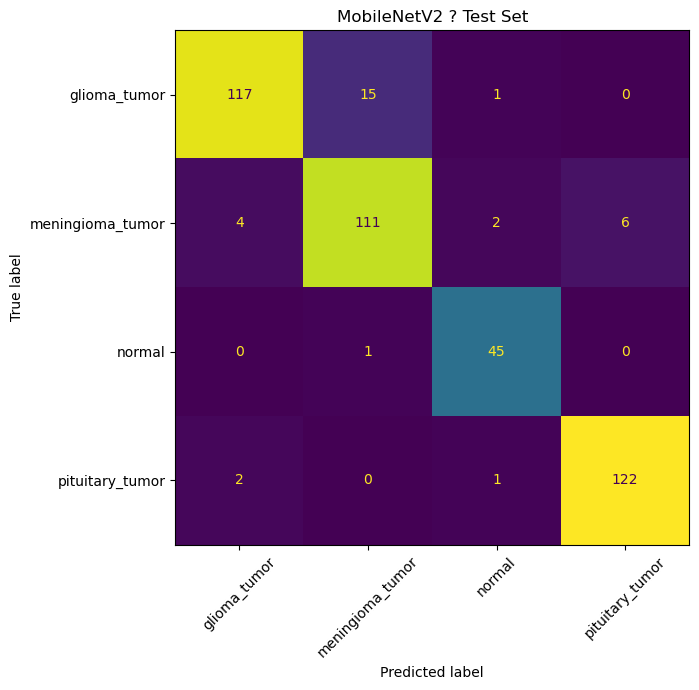

In [13]:
cm=confusion_matrix(all_labels,all_predictions,labels=list(range(len(class_names))))
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)
fig,ax=plt.subplots(figsize=(8,7))
disp.plot(ax=ax,xticks_rotation=45,values_format="d",colorbar=False)
ax.set_title("MobileNetV2 ? Test Set")
plt.tight_layout()
plt.show()


## 7. Optional: save predictions for later comparison


## 8. Inspect misclassified images

This lists every test image whose predicted class differs from its true class and displays the images for visual inspection.


Misclassified images: 32 of 427


,filepath,true_label,predicted_label,confidence
385,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.963220
171,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,pituitary_tumor,0.924493
74,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,glioma_tumor,0.913489
244,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,pituitary_tumor,0.904812
399,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.848162
194,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.810669
162,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.809611
398,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.806844
188,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,pituitary_tumor,glioma_tumor,0.729351
230,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,normal,0.714620


NameError: name 'np' is not defined

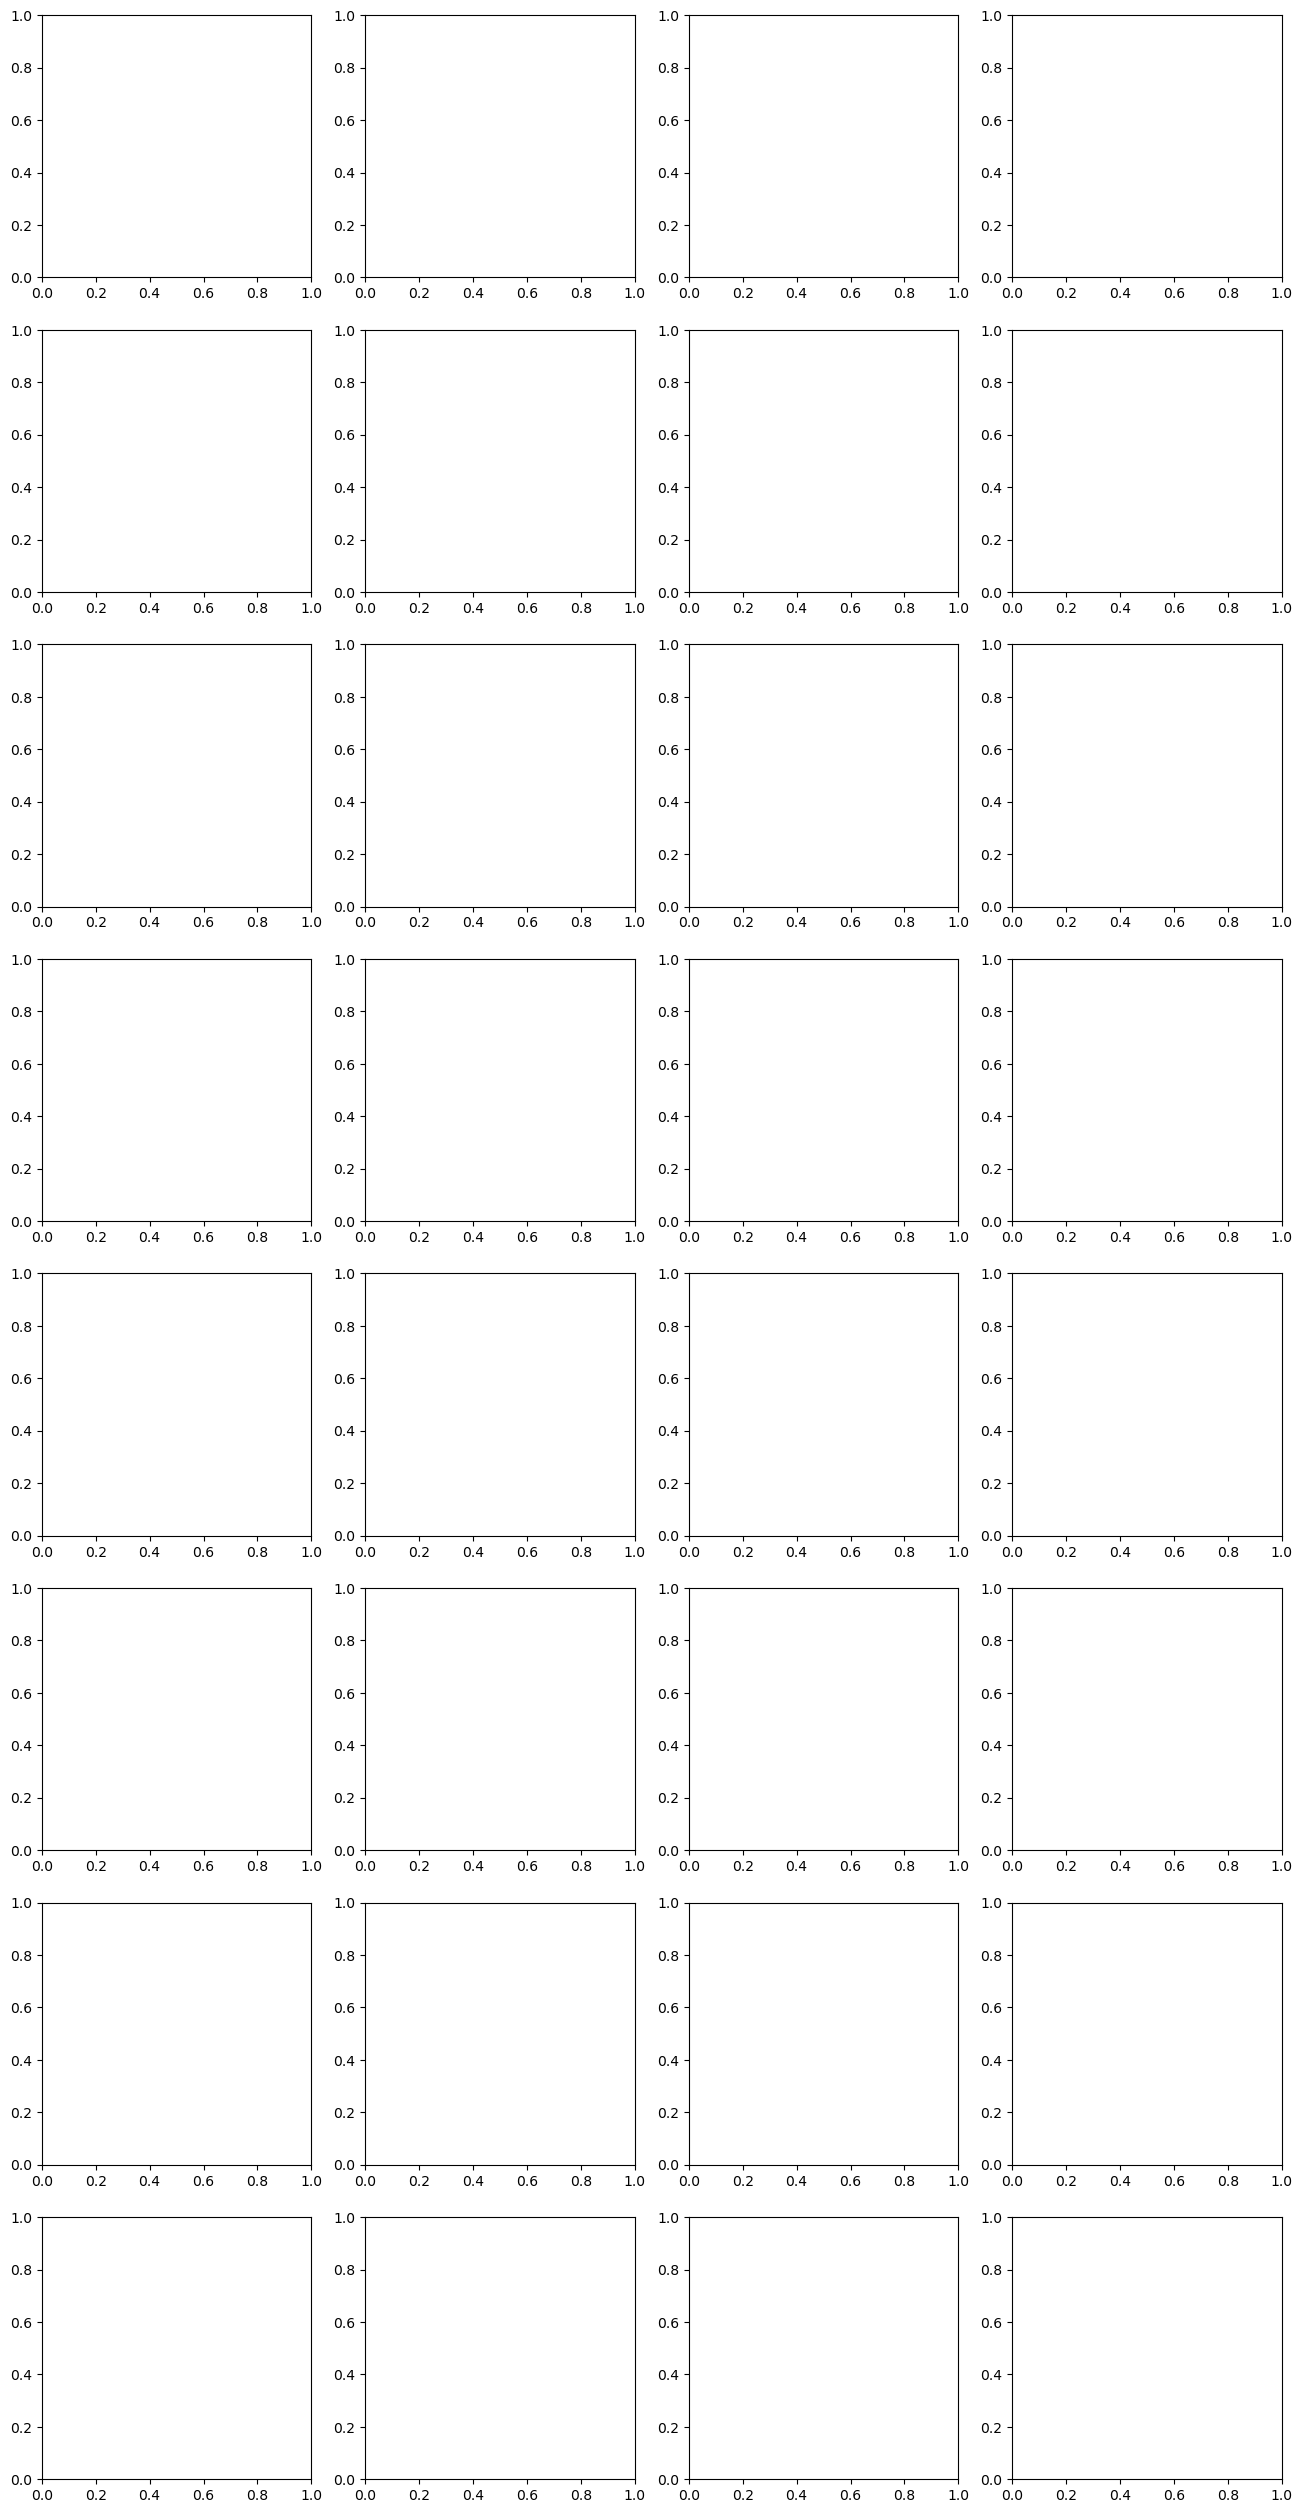

In [14]:
results_df=test_df.copy()
results_df["true_label"]=[idx_to_class[i] for i in all_labels]
results_df["predicted_label"]=[idx_to_class[i] for i in all_predictions]
results_df["confidence"]=all_confidences
misclassified_df=results_df[results_df["true_label"]!=results_df["predicted_label"]].copy()
misclassified_df=misclassified_df.sort_values("confidence",ascending=False)
print(f"Misclassified images: {len(misclassified_df)} of {len(results_df)}")
display(misclassified_df[["filepath","true_label","predicted_label","confidence"]])
misclassified_df.to_csv(Path("trained_models")/"mobilenet_v2_misclassified_images.csv",index=False)
columns=4
rows=(len(misclassified_df)+columns-1)//columns
if rows:
    fig,axes=plt.subplots(rows,columns,figsize=(16,4*rows))
    axes=np.atleast_1d(axes).ravel()
    for ax,(_,row) in zip(axes,misclassified_df.iterrows()):
        image=Image.open(row["filepath"])
        ax.imshow(image,cmap="gray")
        ax.set_title(f"True: {row['true_label']}\nPredicted: {row['predicted_label']} ({row['confidence']:.1%})")
        ax.axis("off")
    for ax in axes[len(misclassified_df):]: ax.axis("off")
    plt.tight_layout()
    plt.show()


In [ ]:
results_df=test_df.copy()
results_df["true_label"]=[idx_to_class[i] for i in all_labels]
results_df["predicted_label"]=[idx_to_class[i] for i in all_predictions]
results_df["correct"]=results_df["true_label"]==results_df["predicted_label"]
prediction_path=Path("trained_models")/"mobilenet_v2_test_predictions.csv"
prediction_path.parent.mkdir(parents=True,exist_ok=True)
results_df.to_csv(prediction_path,index=False)
print("Saved test predictions to:",prediction_path.resolve())


Saved test predictions to: C:\Users\rickv\School\Jaar3\minor\Challenge\Brain-Tumor\brain_tumors\trained_models\mobilenet_v2_test_predictions.csv
